# Using a known spatial pattern to assess the accuracy of `neuromodes.morphometry`

In this notebook we demonstrate the surface-based morphometry of `neuromodes.morphometry`. 

## Imports

In [107]:
import numpy as np
from numpy.typing import NDArray
from scipy import stats
import matplotlib.pyplot as plt

In [108]:
from brainspace.mesh.mesh_creation import build_polydata
from brainspace.vtk_interface.wrappers import BSPolyData

In [109]:
from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf
from neuromodes import mbm as mbm
from nsbutils.plotting import plot_surf

## Parameters/setup

In [110]:
# These can be changed freely
density = '4k'
n_subjects = 255
n_permutations = 100
n_modes = 100
seed = 42
pattern_method = 'mode' # 'vertex' or 'mode'

# These are fixed for this demonstration
statTest = 'ttest'
alternative = 'two-sided'
permutationMethod = 'shuffle_rows'

In [111]:
# Load cortical surface mesh
surf, medmask = fetch_example_surf(density=density)
solver = EigenSolver(surf, mask=medmask).solve(n_modes)
n_verts = solver.n_verts

# Generate BSPolyData object for plotting
# known warning here from brainspace/vtk
bssurf: BSPolyData = build_polydata(surf.v, cells=surf.t) # type: ignore


## Generate data

First, we generate the known difference between the two groups:

In [112]:
# Define the spatial pattern based on the chosen method
if pattern_method == 'vertex':
    spatial_pattern = np.interp(solver.geometry.v[:,1], (solver.geometry.v[:,1].min(), solver.geometry.v[:,1].max()), (-1, 2))
elif pattern_method == 'mode':
    spatial_pattern = (solver.emodes @ (np.arange(n_modes)[:,None]/n_modes)).flatten()
else: 
    raise ValueError(f"Invalid pattern_method: {pattern_method}. Must be 'vertex' or 'mode'.")

# Then the t and p values can be computed from the spatial pattern and the number of subjects
t_expected = spatial_pattern * np.sqrt(n_subjects / 2)
p_expected = 2 * stats.t.sf(np.abs(t_expected), df=2*n_subjects - 2)

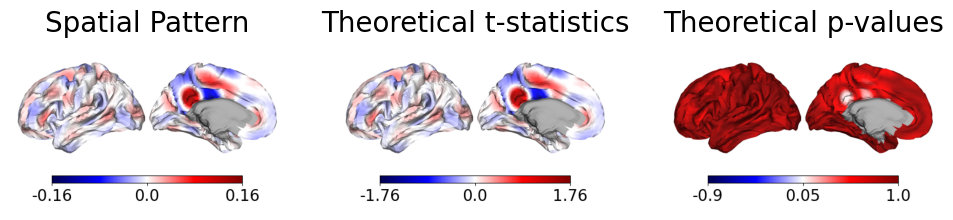

In [113]:
fig, axs = plt.subplots(1, 3, figsize=(12, 4))
plot_surf(bssurf, solver.unmask_data(spatial_pattern), labels=['Spatial Pattern'],
          cmap='seismic', cbar=True, center = 0.00, ax=axs[0])
plot_surf(bssurf, solver.unmask_data(t_expected), labels=['Theoretical t-statistics'],
          cmap='seismic', cbar=True, center = 0.00, ax=axs[1])
plot_surf(bssurf, solver.unmask_data(p_expected), labels=['Theoretical p-values'],
          cmap='seismic', cbar=True, center = 0.05, ax=axs[2])

Then, we generate noise with that known difference: 

In [114]:
# Here we generate synthetic data for two groups of subjects, with the expected spatial pattern added to one group. 
rng = np.random.default_rng(seed=seed)

# 1. Generate baseline noise and z-score across subjects (axis=1, ddof=1)
a_noise: NDArray = stats.zscore(rng.normal(size=(n_verts, n_subjects)), axis=1, ddof=1) # type: ignore
b_noise: NDArray = stats.zscore(rng.normal(size=(n_verts, n_subjects)), axis=1, ddof=1) # type: ignore

# 2. Enforce exact pooled variance = 1 across the two groups
sd = np.sqrt((np.var(a_noise, axis=1, ddof=1) + np.var(b_noise, axis=1, ddof=1)) / 2)

# 3. Construct group matrices with exact spatial pattern offset
data_a = a_noise / sd[:, np.newaxis]
data_b = b_noise / sd[:, np.newaxis] + spatial_pattern[:, np.newaxis]

We can visualise the first few example maps:

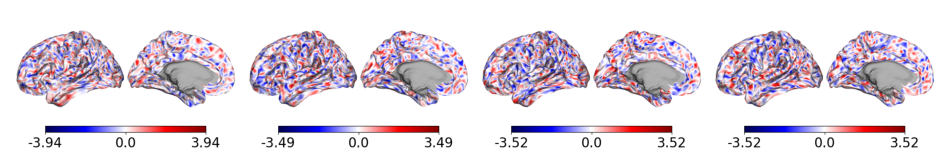

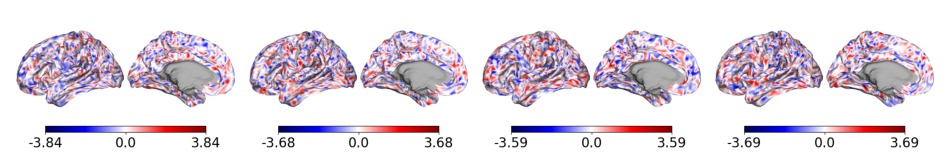

In [115]:
plot_surf(bssurf, solver.unmask_data(data_a[:,:4]), cmap='seismic', cbar=True, center=0)
plot_surf(bssurf, solver.unmask_data(data_b[:,:4]), cmap='seismic', cbar=True, center=0)

## Vertex-level t-test (surface based morphometry)

`neuromodes.morphometry` requires us to explicity construct design, response, and contrast matrices:

In [116]:
response = np.vstack((data_a.T, data_b.T))
design = np.kron(np.array([[1,-1], [1,1]]), np.ones((n_subjects, 1)))
contrast = np.array([[0, 1]])

We actually compute the vertex-level t-statistic using the function `mbm_generate_stat_maps`: 

In [117]:
t_observed = mbm.mbm_generate_stat_maps(design, response, contrast, statTest)
pattern_observed = t_observed / np.sqrt(n_subjects / 2)

We can visualise the theoretical and observed vertex-wise t-statistics: 

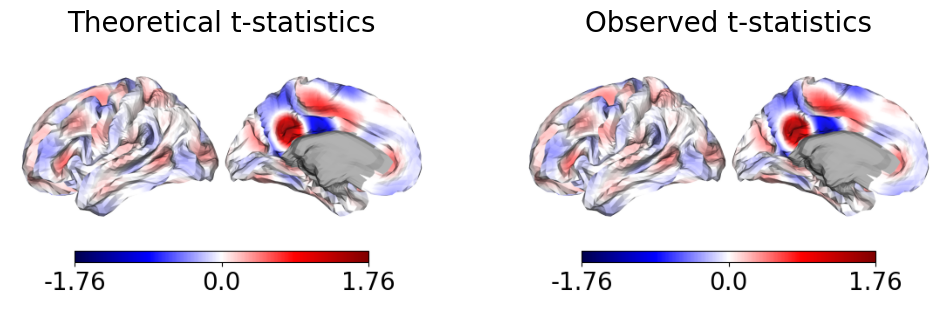

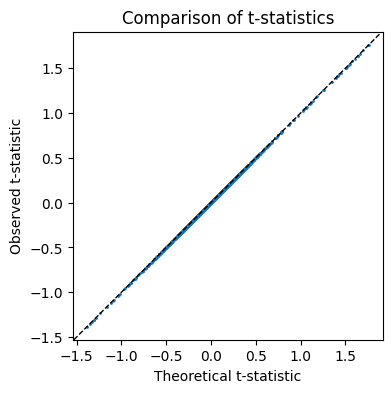

In [118]:
fig, axs = plt.subplots(1, 2, figsize=(12, 6))
plot_surf(bssurf, solver.unmask_data(t_expected), labels=['Theoretical t-statistics'], 
          cmap='seismic', cbar=True, center=0.00, ax=axs[0])
plot_surf(bssurf, solver.unmask_data(t_observed), labels=['Observed t-statistics'], 
          cmap='seismic', cbar=True, center=0.00, ax=axs[1])
plt.show()

fig, ax = plt.subplots(1, 1, figsize=(4, 4))
ax.scatter(t_expected, t_observed, s=1)
ax.axline((0,0), slope=1, color='k', linestyle='--', linewidth=1)
ax.axis('equal')
ax.set_xlabel('Theoretical t-statistic')
ax.set_ylabel('Observed t-statistic')
ax.set_title('Comparison of t-statistics')
plt.show()


And see that the error is at the level of machine precision: 

In [119]:
max_abs_error = np.max(np.abs(t_observed - t_expected))
print(f"Max error from theoretical t-stat: {max_abs_error:.2e}")

Max error from theoretical t-stat: 1.44e-15


## Generating non-parametric p-values by permutation testing

First, we generate the null t-statistic maps. This is done by shuffling the design matrix (equivalent to randomising the group allocation in this example) and then computing new t-statistics at each vertex for each permutation. We use the function `mbm_generate_stat_maps` for this: 

In [120]:
# This takes around n_permutations/10 seconds
t_permuted = mbm.mbm_generate_stat_maps(design, response, contrast, statTest, 
                                     n_permutations=n_permutations, 
                                     permutationMethod=permutationMethod, 
                                     seed=seed)

We can then compute the p-value at each vertex. In the present example, we do this using the simplest approach of counting how many null t-statistics are above/below the observed statistic. This is done with the function `mbm_calc_p_vals`: 

In [121]:
p_observed = mbm.mbm_calc_p_vals(t_observed, t_permuted, alternative, None)

We can compare the expected and observed p-values: 

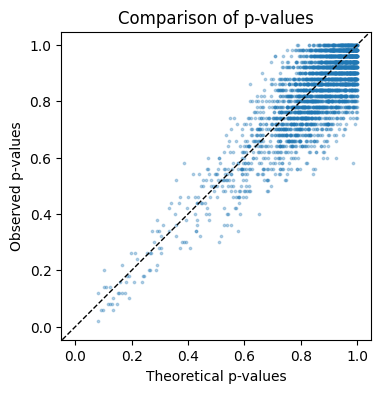

In [122]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))

ax.scatter(p_expected, p_observed, alpha=0.3, s=3)
ax.axis("equal")
ax.axline((0, 0), slope=1, color="k", linestyle="--", linewidth=1)
ax.set_xlabel("Theoretical p-values")
ax.set_ylabel("Observed p-values")
ax.set_title("Comparison of p-values")

plt.show()

We can visualise the p-value at each vertex. As expected, the p-value is high (~1) when the spatial pattern is near zero, and is low (~0) when the spatial pattern is far from zero. 

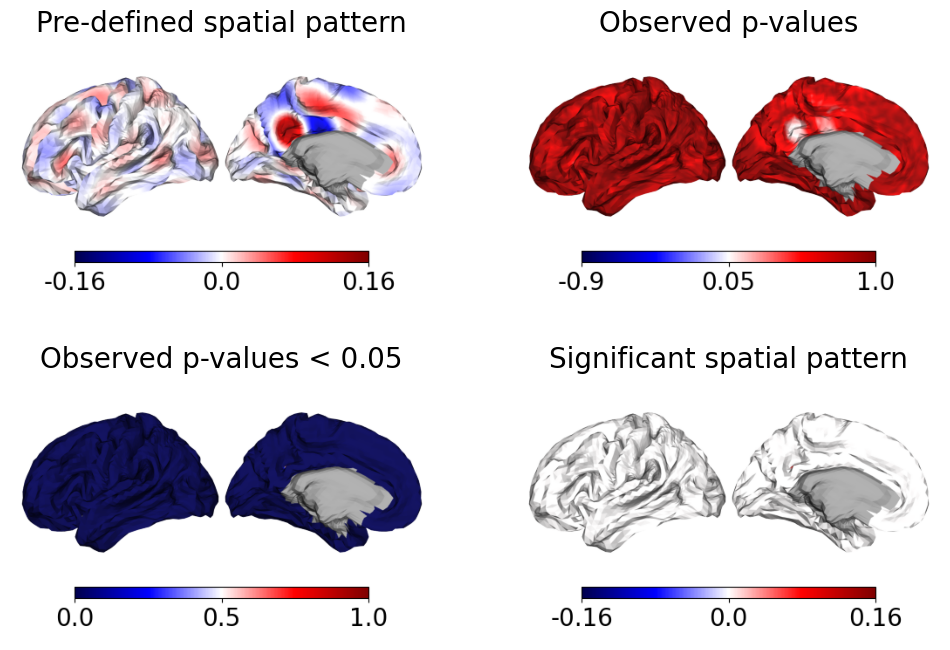

In [123]:
fig, axs = plt.subplots(2, 2, figsize=(12, 8))
axs = axs.flatten()

plot_surf(bssurf, solver.unmask_data(spatial_pattern), labels=['Pre-defined spatial pattern'],
          cmap='seismic', center=0, cbar=True, ax=axs[0])

plot_surf(bssurf, solver.unmask_data(p_observed), labels=['Observed p-values'],
          cmap='seismic', center=0.05, cbar=True, ax=axs[1])

plot_surf(bssurf, solver.unmask_data(p_observed<0.05), labels=['Observed p-values < 0.05'],
          cmap='seismic', color_range=(0.00, 1.00), cbar=True, ax=axs[2])

plot_surf(bssurf, solver.unmask_data((p_observed<0.05) * pattern_observed), labels=['Significant spatial pattern'], 
          cmap='seismic', center=0, cbar=True, ax=axs[3])

We can compare the observed and expected t-statistics and p-values: 

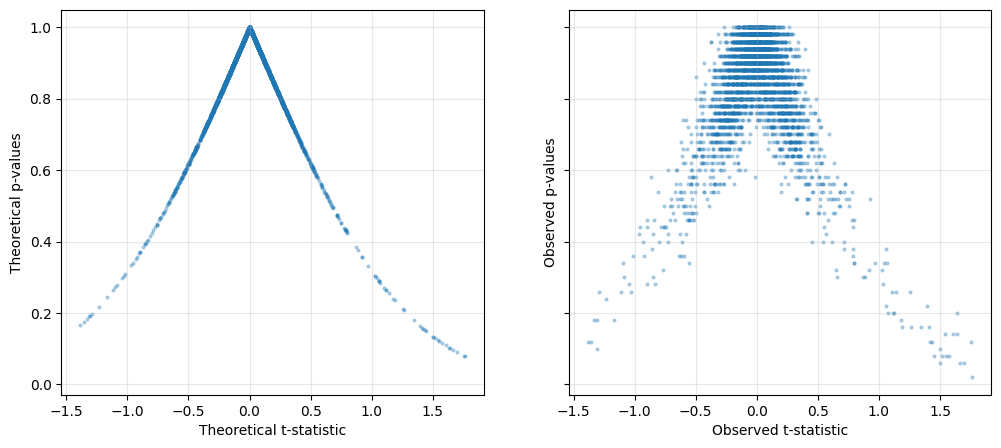

In [124]:
fig, axs = plt.subplots(1, 2, figsize=(12,5), sharex=True, sharey=True)
ax = axs[0]
ax.scatter(t_expected, p_expected, s=4, alpha=0.3)
ax.set_xlabel('Theoretical t-statistic')
ax.set_ylabel('Theoretical p-values')
ax.grid(alpha=0.3)

ax = axs[1]
ax.scatter(t_observed, p_observed, s=4, alpha=0.3)
ax.set_xlabel('Observed t-statistic')
ax.set_ylabel('Observed p-values')
ax.grid(alpha=0.3)

plt.show()

## Mode-level statistics (Mode Based Morphometry)

We can do a similar analysis but at the mode level rather than the vertex level. 

First, find the empirical loadings: 

In [125]:
beta_a = solver.decompose(data_a)
beta_b = solver.decompose(data_b)
response_mode = np.vstack((beta_a.T, beta_b.T))

Then find the empirical t-stat for each mode: 

In [126]:
t_mode = mbm.mbm_generate_stat_maps(design, response_mode, contrast, statTest)
pattern_mode = t_mode / np.sqrt(n_subjects / 2)

The null t-stats for each mode: 

In [127]:
t_mode_nulls = mbm.mbm_generate_stat_maps(design, response_mode, contrast, statTest, 
                                           n_permutations=n_permutations, 
                                           permutationMethod='shuffle_rows', 
                                           seed=seed)

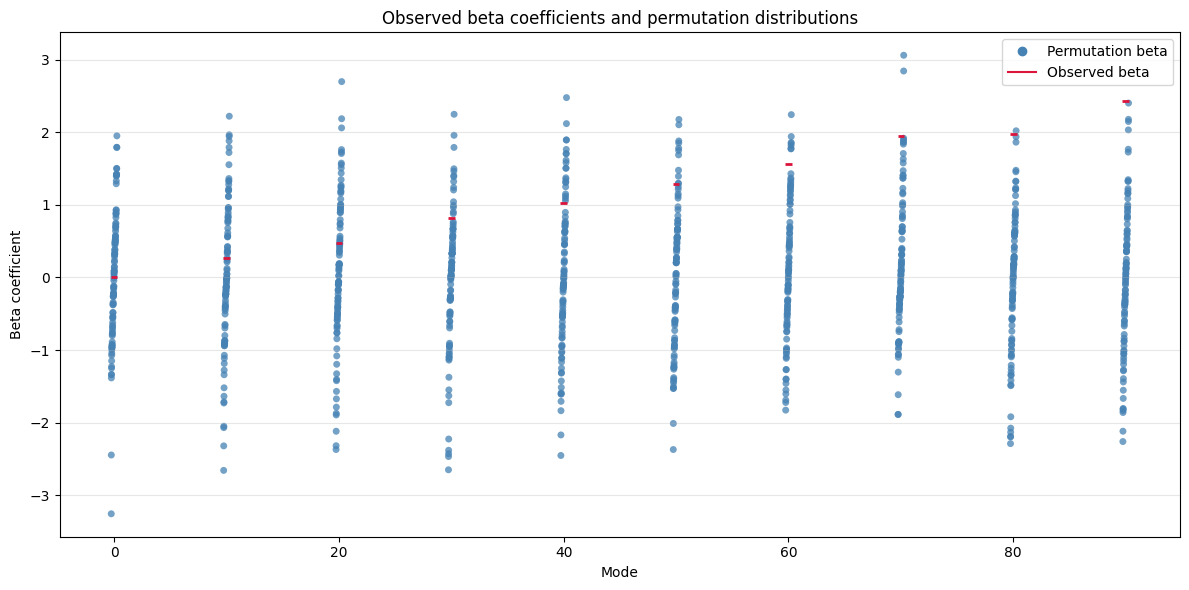

In [128]:
fig, ax = plt.subplots(figsize=(12, 6))

# Swarm-like horizontal offsets for permutation values
offsets = np.linspace(-0.25, 0.25, n_permutations)

for i in range(0, n_modes, 10):
    ax.scatter(
        i + offsets,
        np.sort(t_mode_nulls[i, :]),
        color='steelblue',
        alpha=0.75,
        s=25,
        edgecolor='none'
    )

    # Corresponding observed beta
    ax.hlines(
        t_mode[i],
        i - 0.3,
        i + 0.3,
        color='crimson',
        linewidth=2
    )

ax.set_xlabel('Mode')
ax.set_ylabel('Beta coefficient')
ax.set_title('Observed beta coefficients and permutation distributions')
ax.legend(
    handles=[
        plt.Line2D([], [], color='steelblue', marker='o',
                   linestyle='None', label='Permutation beta'),
        plt.Line2D([], [], color='crimson',
                   label='Observed beta')
    ]
)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

And the p-values: 

In [129]:
p_mode = mbm.mbm_calc_p_vals(t_mode, t_mode_nulls, alternative, None)

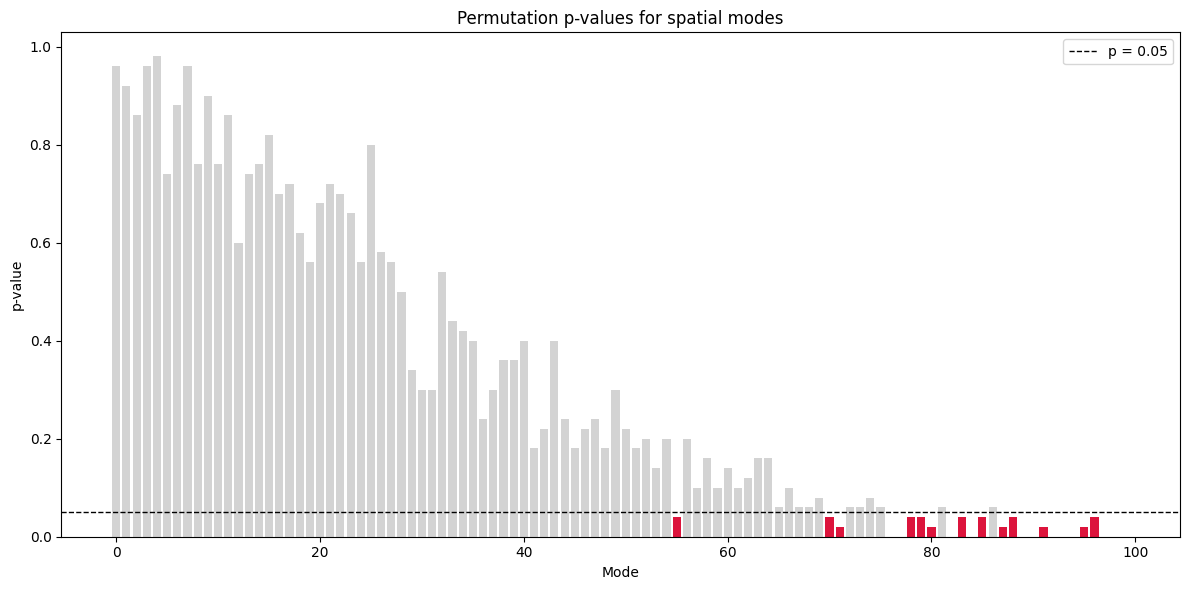

In [130]:
colors = np.where(p_mode < 0.05, 'crimson', 'lightgray')

fig, ax = plt.subplots(figsize=(12, 6))
ax.bar(range(n_modes), p_mode, color=colors)
ax.axhline(0.05, color='black', linestyle='--', linewidth=1, label='p = 0.05')

ax.set_xlabel('Mode')
ax.set_ylabel('p-value')
ax.set_title('Permutation p-values for spatial modes')
ax.legend()
plt.tight_layout()
plt.show()

In [131]:
# Have to rescale modes by their mass-weighted L2 norm to ensure that units/magnitudes are correct
# This arises when the data is projected onto the modes using the mass matrix
_modes_rescaled = solver.emodes * np.linalg.norm(solver.mass @ solver.emodes, axis=0)
mode_pattern_all = (_modes_rescaled @ (pattern_mode)[:, np.newaxis]).flatten()
mode_pattern_sig = (_modes_rescaled @ (pattern_mode * (p_mode < 0.05))[:, np.newaxis]).flatten()

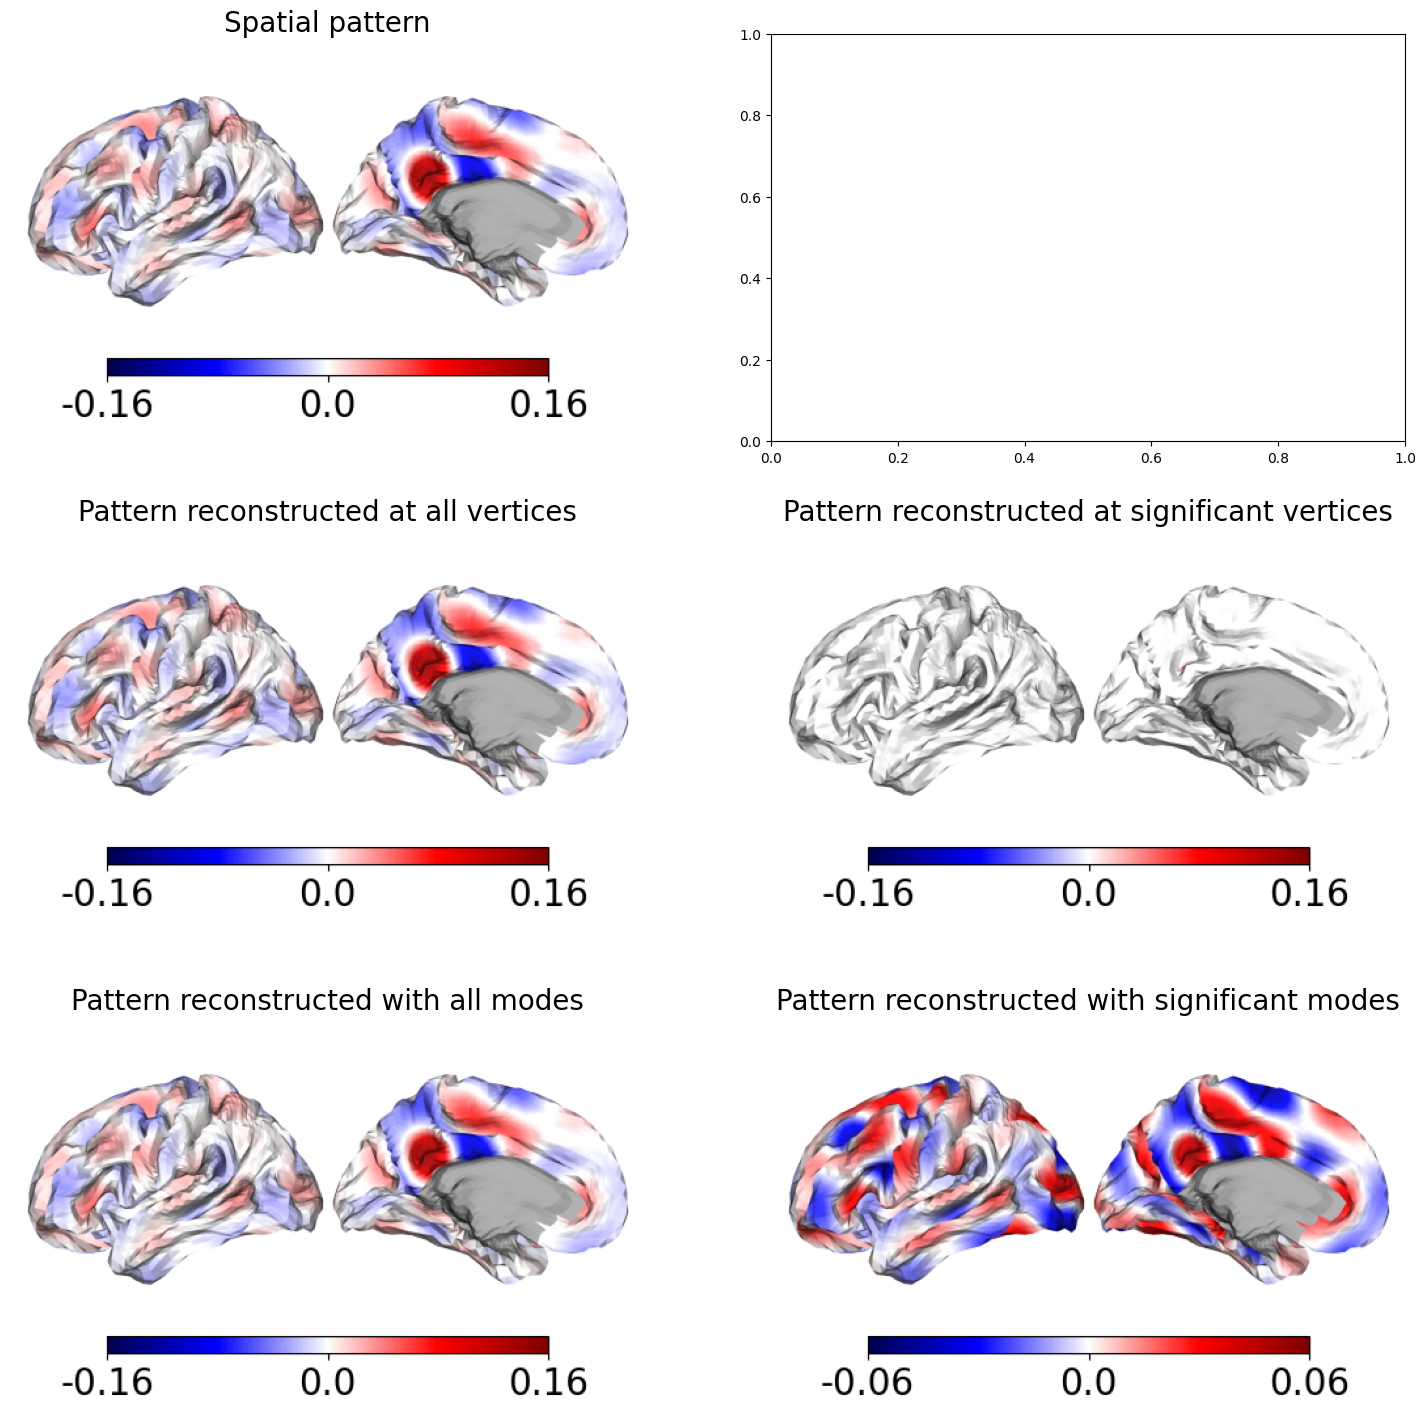

In [133]:
fig, axs = plt.subplots(3, 2, figsize=(18, 18))
axs = axs.flatten()

plot_surf(bssurf, solver.unmask_data(spatial_pattern), labels=['Spatial pattern'],
          cmap='seismic', center=0, cbar=True, ax=axs[0])

plot_surf(bssurf, solver.unmask_data(pattern_observed), labels=['Pattern reconstructed at all vertices'],
          cmap='seismic', center=0, cbar=True, ax=axs[2])

plot_surf(bssurf, solver.unmask_data((p_observed<0.05) * pattern_observed), labels=['Pattern reconstructed at significant vertices'], 
          cmap='seismic', center=0, cbar=True, ax=axs[3])          

plot_surf(bssurf, solver.unmask_data(mode_pattern_all), labels=['Pattern reconstructed with all modes'],
          cmap='seismic', center=0, cbar=True, ax=axs[4])

plot_surf(bssurf, solver.unmask_data(mode_pattern_sig), labels=['Pattern reconstructed with significant modes'],
          cmap='seismic', center=0, cbar=True, ax=axs[5])
